# 6.1 Pad footing under internal column B2

The soil is represented only by its presumed bearing pressure. The pad is then designed as reinforced concrete.

| Step | Check | Reference |
|:--|:--|:--|
| 1 | Plan size: characteristic loads ≤ presumed bearing pressure | EN 1997-1 6.5.2.4 |
| 2 | Cover on blinding, effective depth | EC2 4.4.1.3(4) |
| 3, 4 | ULS net pressure, bending at the column face | EC2 5.3.2.2(3), 6.1 |
| 5 | Inclined-crack bar force, anchorage | EC2 9.8.2.2 |
| 6 | One-way shear at d | EC2 6.2.2 |
| 7, 8 | Punching at the face and at every perimeter within 2d | EC2 6.4.4(2), 6.4.5(3) |
| 9, 10 | Cracking, starter bars and laps | EC2 7.3, 8.4, 8.7 |

In [1]:
import sys; sys.path.insert(0, '..')
from ec2.setup import *

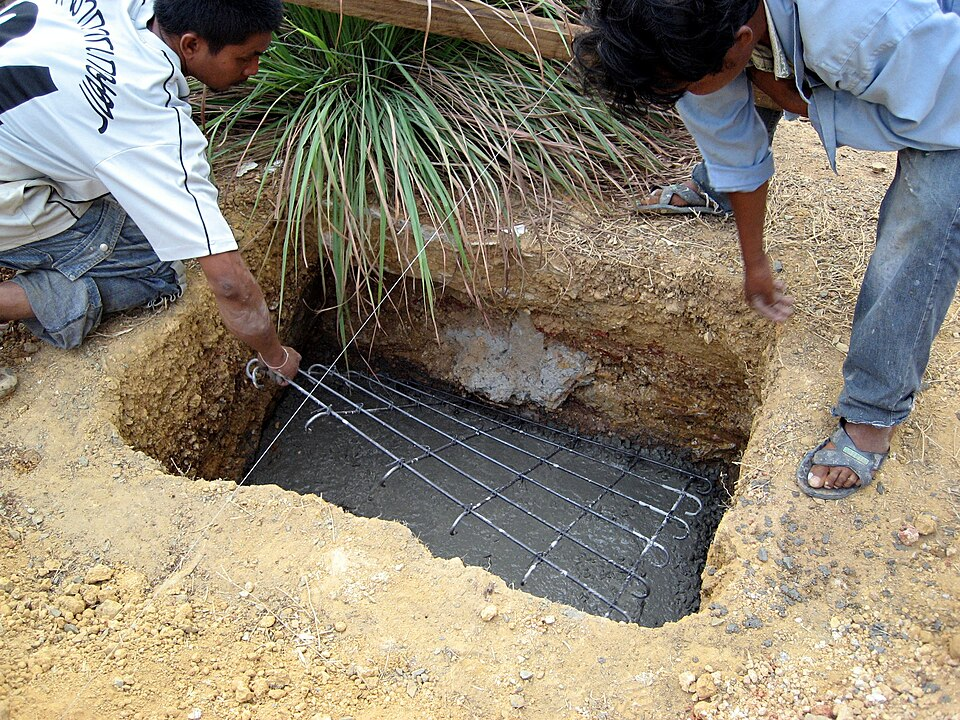

*Bottom mesh being lowered into a footing pit. On site the bars must stand on spacers to give the cover calculated below.* <br><small>Photo: Khaosaming, [CC BY-SA 3.0](https://creativecommons.org/licenses/by-sa/3.0), via [Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Thai_House_Footing_Base_Rebar_Mesh.JPG).</small>

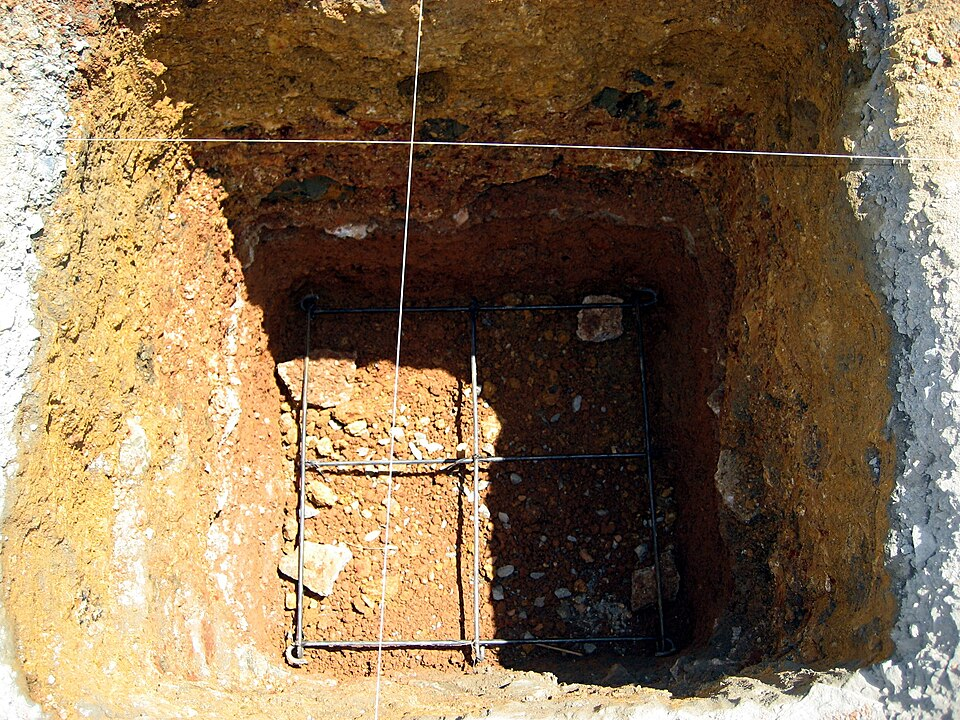

*Excavated column base with the first reinforcement.* <br><small>Photo: Khaosaming, [CC BY-SA 3.0](https://creativecommons.org/licenses/by-sa/3.0), via [Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Thai_House_Column_Foot_Rebar.JPG).</small>

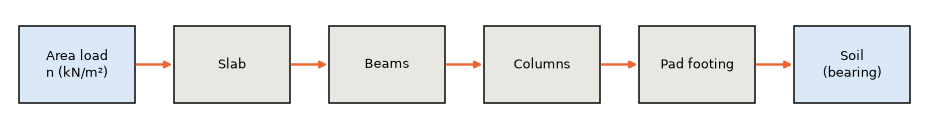

In [2]:
photo("footing_mesh", "Bottom mesh being lowered into a footing pit. On site the bars must stand on spacers to give the cover calculated below.")
photo("column_foot", "Excavated column base with the first reinforcement.")
P.sketch_load_path()

## Why these checks

- **Bearing** uses unfactored (characteristic) loads, because the presumed pressure already contains the geotechnical margin.
- **Strength** uses ULS loads. The self-weight of the pad goes straight into the ground and does not bend it, so the *net* pressure is N/A.
- Pressure inside a punching perimeter is deducted, because it never crosses that perimeter.

In [3]:
def pad_design(col, line, j, B, hp, phi, spacing, starter=16, ground="blinding"):
    """Square pad under a ground-storey column with axial load and a uniaxial base moment."""
    br = BRIEF; c1, c2 = br["col"]; t = PJ.takedown(col)
    Mk, Md = PJ.column_joint(line, j, 1, 1)["M"] / 2, PJ.column_joint(line, j)["M"] / 2
    s = Sheet(f"Pad footing, column {col}", element=f"Pad {col}, {B/1000:.2f} m square × {hp} mm")
    D.materials(s, br["fck"], br["fyk"], br["ndp"])
    # ---- plan size (SLS)
    s.let("G_k", t["G"], "kN", "Permanent column load (Notebook 5.1)"); s.let("Q_k", t["Q"], "kN", "Variable column load"); s.let("M_k", Mk, "kN·m", "Characteristic base moment (half the column-top moment)")
    s.let("q_allow", br["bearing"], "kN/m²", "Presumed gross bearing pressure (ground investigation)", "EN 1997-1 6.5.2.4"); s.let("B", B / 1000, "m", "Side of the square pad"); s.let("h", hp, "mm", "Thickness"); s.let("q_ob", br["overburden"], "kN/m²", "Overburden (project input)")
    s.calc("N_k", "G_k + Q_k", "kN", "EN 1990 Exp. (6.14b)"); s.calc("W_k", "(25*h/1000 + q_ob)*B**2", "kN", "EN 1991-1-1 Table A.1", "Pad self-weight and overburden")
    s.calc("e", "M_k/(N_k + W_k)", "m", "", "Eccentricity"); s.calc("e_lim", "B/6", "m", "Middle third: no uplift"); s.check("e", "<=", "e_lim", "resultant within the middle third", "Statics; EN 1997-1 6.5.4")
    s.calc("p_max", "(N_k + W_k)/B**2*(1 + 6*e/B)", "kN/m²", "Statics"); s.calc("p_min", "(N_k + W_k)/B**2*(1 - 6*e/B)", "kN/m²", "Statics"); s.check("p_max", "<=", "q_allow", "bearing pressure", "EN 1997-1 6.5.2.4"); s.show("1. Plan size: characteristic loads")
    # ---- cover, depth
    c = D.cover(s, br["exposure_ground"], phi, ground=ground); s.calc("d_x", "h - c_nom - phi/2", "mm"); s.calc("d_y", "h - c_nom - 1.5*phi", "mm"); s.calc("d_m", "(d_x + d_y)/2", "mm", "EC2 Exp. (6.32)", "Mean effective depth"); s.show("2. Effective depth")
    # ---- ULS pressure
    s.calc("N_Ed", "1.35*G_k + 1.5*Q_k", "kN", "EN 1990 Exp. (6.10)"); s.let("M_Ed_0", Md, "kN·m", "Base moment, ULS"); s.calc("p_Ed", "N_Ed/B**2 + 6*M_Ed_0/B**3", "kN/m²", "EC2 6.4.4(2)", "Largest net pressure. The weight of the pad and overburden cancels"); s.note("The largest edge pressure is applied over the whole cantilever, which is conservative.")
    s.let("c_1", c1, "mm", "Column"); s.calc("a", "(B - c_1/1000)/2", "m", "EC2 5.3.2.2(3)", "Cantilever from the column face"); s.calc("M_face", "p_Ed*a**2/2", "kN·m/m", "EC2 5.3.2.2(3)"); s.show("3. ULS pressure and moment at the column face")
    # ---- bending
    d = s["d_y"]; As, _ = D.flexure(s, s["M_face"], 1000, d, label="(inner layer, both directions detailed alike)")
    s.let("phi_min_f", 8, "mm", "", "EC2 9.8.2.1(1)"); s.let("phi", phi, "mm"); s.check("phi", ">=", "phi_min_f", "minimum bar in a footing", "EC2 9.8.2.1(1)"); s.let("s_prov", spacing, "mm"); s.calc("A_s_prov", "pi*phi**2/4*1000/s_prov", "mm²/m"); s.check("A_s_prov", ">=", "A_s_req", "bending steel", "EC2 6.1, 9.2.1.1"); s.provide(f"H{phi} @ {spacing} mm both ways, bottom"); Ap = s["A_s_prov"]; s.show("4. Bending")
    # ---- inclined crack model
    s.calc("z_i", "0.9*d_y", "mm", "EC2 9.8.2.2(3)"); s.calc("x_m", "B*1000/2 - 0.35*c_1", "mm", "EC2 9.8.2.2(3), e = 0.15b; method as JRC EUR 26566 4.2.1"); s.calc("F_s_max", "p_Ed/1000*x_m*(x_m/2)/z_i", "kN/m", "EC2 Exp. (9.13)", "Largest bar force, R·z_e/z_i"); s.calc("A_s_F", "F_s_max*1000/f_yd", "mm²/m"); s.check("A_s_prov", ">=", "A_s_F", "steel for the inclined-crack model", "EC2 9.8.2.2")
    s.calc("x_min", "h/2", "mm", "EC2 9.8.2.2(5)"); s.calc("z_e", "x_m - x_min/2", "mm", "EC2 9.8.2.2(3)"); s.calc("F_s", "p_Ed/1000*x_min*z_e/z_i", "kN/m", "EC2 Exp. (9.13)", "Force to anchor at x_min")
    s.calc("sigma_F", "F_s*1000/A_s_prov", "N/mm²"); lb = D.anchorage(s, phi, s["sigma_F"]); s.calc("l_b_av", "x_min - c_nom", "mm", "EC2 9.8.2.2(4)"); s.check("l_b_av", ">=", "l_bd", "straight bar anchorage", "EC2 9.8.2.2"); s.show("5. Bar force and anchorage")
    # ---- one-way shear
    s.calc("V_Ed", "p_Ed*(a - d_y/1000)", "kN/m", "EC2 6.2.1(8)", "At d from the column face"); D.shear_resistance(s, 1000, d, Ap); s.check("V_Ed", "<=", "V_Rd_c", "one-way shear, no links", "EC2 6.2.2"); s.show("6. One-way shear")
    # ---- punching
    s.let("c_2", c2, "mm"); s.calc("u_0", "2*(c_1 + c_2)", "mm", "EC2 6.4.5(3)"); s.calc("W_1", "c_1**2/2 + c_1*c_2 + 4*c_2*d_m + 16*d_m**2 + 2*pi*d_m*c_1", "mm²", "EC2 Exp. (6.41)"); s.calc("u_1", "2*(c_1 + c_2) + 4*pi*d_m", "mm", "EC2 6.4.2(1)"); s.let("k_t", F.k_table61(c1 / c2), "", "", "EC2 Table 6.1")
    s.calc("beta", "1 + k_t*M_Ed_0*1e6/(N_Ed*1000)*u_1/W_1", "", "EC2 Exp. (6.39)"); s.calc("v_Ed_0", "beta*N_Ed*1000/(u_0*d_m)", "N/mm²", "EC2 Exp. (6.53), no soil relief"); s.calc("nu", "0.6*(1 - f_ck/250)", "", "EC2 Exp. (6.6N)"); s.let("k_v", br["ndp"]["vmax"], "", br["ndp"]["name"], "EC2 6.4.5(3), NA"); s.let("f_cd_p", s["f_ck"] / s["gamma_c"], "N/mm²", "f_cd with α_cc = 1.0 for shear", "NA 3.1.6(1)"); s.calc("v_Rd_max", "k_v*nu*f_cd_p", "N/mm²", "EC2 6.4.5(3), NA"); s.check("v_Ed_0", "<=", "v_Rd_max", "punching at the column face", "EC2 6.4.5(3)")
    s.let("rho", Ap / (1000 * s["d_m"]), "", "Mean steel ratio √(ρ_x ρ_y)", "EC2 6.4.4(1)"); rows = F.punching_scan(s["N_Ed"], Md, B, B, c1, c2, s["d_m"], s["rho"], s["f_ck"]); w = max(rows, key=lambda r: r[5])
    s.show("7. Punching shear at the column face")
    pick = rows[:: max(1, len(rows) // 8)]; table([[f"{r[0]/s['d_m']:.2f}d", round(r[0]), round(r[1]), round(r[2], 1), round(r[3], 3), round(r[4], 3), round(r[5], 2)] for r in pick], ["a", "a (mm)", "u (mm)", "V_Ed,red (kN)", "v_Ed (N/mm² = MPa)", "v_Rd (N/mm² = MPa)", "ratio"], "Control perimeters within 2d (EC2 6.4.4(2), Exp. 6.48 to 6.51)")
    P.punching_plot(rows, s["d_m"])
    s.let("a_cr", w[0], "mm", "Critical perimeter"); s.let("v_Ed_p", w[3], "N/mm²", "", "EC2 Exp. (6.51)"); s.let("v_Rd_p", w[4], "N/mm²", "", "EC2 Exp. (6.50)"); s.check("v_Ed_p", "<=", "v_Rd_p", f"punching, worst of {len(rows)} perimeters", "EC2 6.4.4(2)"); s.show("8. Punching shear within 2d")
    # ---- cracking
    s["A_s_ult"] = As; D.crack(s, s["G_k"], s["Q_k"], PSI[br["category"]][2], As, Ap, spacing, hp); s.show("9. Cracking")
    # ---- starters
    D.anchorage(s, starter, compression=True, label="starter bar, full stress in compression"); s.calc("l_av", "h - c_nom - 2*%d" % phi, "mm", "", "Straight depth above the mat (bends do not count in compression, EC2 8.4.1(3))"); s.check("l_av", ">=", "l_bd", "starter bar anchorage", "EC2 8.4.4")
    _, lap = D.anchorage(s, starter, lap_pct=100, label="column lap"); s.provide(f"8H{starter} starters, lap {math.ceil(lap / 25) * 25} mm above the pad"); s.show("10. Starter bars")
    P.pad(B, B, hp, c1, c2, s["d_m"], phi, spacing, c, f"Pad {col}"); s.summary(); return s

### Input guide

| Name | Meaning | Unit | Expected |
|:--|:--|:--|:--|
| `B`, `hp` | Side of the square pad; thickness | mm | > 0 |
| `phi`, `spacing` | Bottom bars both ways | mm | 8, 10, 12, 16, 20, 25, 32 |
| `starter` | Column starter bar | mm | match the column bar |
| `ground` | Surface the pad is cast on |  | `"blinding"` or `"soil"` |

Loads, bearing pressure and materials come from `BRIEF`: see the guide in Notebook 0.1.

In [4]:
# INPUTS: edit only this cell, then run the cells below it
# Column loads, bearing pressure and materials come from BRIEF in ec2/project.py
pad = dict(B=2700, hp=650, phi=16, spacing=200, starter=16, ground="blinding")      # side, thickness, bar, spacing, starter bar (mm); "blinding" or "soil"

## Pad footing, column B2

*Project:* EC2 design guide &nbsp;|&nbsp; *Element:* Pad B2, 2.70 m square × 650 mm

### Materials

| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 Table 3.1 | Concrete cylinder strength (project input): $f_{ck}$ | $f_{ck} = 30$ N/mm²<br><small>(= 30 MPa)</small> |
| EC2 3.2.2(3) | Steel yield strength (project input): $f_{yk}$ | $f_{yk} = 500$ N/mm²<br><small>(= 500 MPa)</small> |
| EC2 2.4.2.4, Table 2.1N | Partial factor, concrete: $\gamma_{c}$ | $\gamma_{c} = 1.5$  |
| EC2 2.4.2.4, Table 2.1N | Partial factor, reinforcement: $\gamma_{s}$ | $\gamma_{s} = 1.15$  |
| EC2 3.1.6(1), NA | Flexure and axial load (UK National Annex): $\alpha_{cc}$ | $\alpha_{cc} = 0.85$  |
| EC2 Exp. (3.15) | $f_{cd} = \dfrac{\alpha_{cc}\,f_{ck}}{\gamma_{c}}$<br>$\quad = \dfrac{0.85\times 30}{1.5}$ | $\mathbf{f_{cd} = 17}$ N/mm²<br><small>(= 17 MPa)</small> |
| EC2 3.2.7, Fig. 3.8 | $f_{yd} = \dfrac{f_{yk}}{\gamma_{s}}$<br>$\quad = \dfrac{500}{1.15}$ | $\mathbf{f_{yd} = 434.8}$ N/mm²<br><small>(= 434.8 MPa)</small> |
| EC2 Table 3.1 | $f_{ctm} = 0.3\,f_{ck}^{2/3}$<br>$\quad = 0.3\times 30^{2/3}$ | $\mathbf{f_{ctm} = 2.896}$ N/mm²<br><small>(= 2.896 MPa)</small> |
| EC2 3.2.7(4) | Steel modulus: $E_{s}$ | $E_{s} = 200000$ N/mm²<br><small>(= 200000 MPa)</small> |


### 1. Plan size: characteristic loads

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Permanent column load (Notebook 5.1): $G_{k}$ | $G_{k} = 772$ kN |
|  | Variable column load: $Q_{k}$ | $Q_{k} = 421.3$ kN |
|  | Characteristic base moment (half the column-top moment): $M_{k}$ | $M_{k} = 5.028$ kN·m |
| EN 1997-1 6.5.2.4 | Presumed gross bearing pressure (ground investigation): $q_{allow}$ | $q_{allow} = 200$ kN/m²<br><small>(= 200000 Pa)</small> |
|  | Side of the square pad: $B$ | $B = 2.7$ m |
|  | Thickness: $h$ | $h = 650$ mm |
|  | Overburden (project input): $q_{ob}$ | $q_{ob} = 9$ kN/m²<br><small>(= 9000 Pa)</small> |
| EN 1990 Exp. (6.14b) | $N_{k} = G_{k} + Q_{k}$<br>$\quad = 772 + 421.3$ | $\mathbf{N_{k} = 1193.4}$ kN |
| EN 1991-1-1 Table A.1 | Pad self-weight and overburden<br>$W_{k} = \left(\dfrac{25\,h}{1000} + q_{ob}\right)\,B^{2}$<br>$\quad = \left(\dfrac{25\times 650}{1000} + 9\right)\times 2.7^{2}$ | $\mathbf{W_{k} = 184.1}$ kN |
|  | Eccentricity<br>$e = \dfrac{M_{k}}{N_{k} + W_{k}}$<br>$\quad = \dfrac{5.028}{1193.4 + 184.1}$ | $\mathbf{e = 0.00365}$ m |
| Middle third: no uplift | $e_{lim} = \dfrac{B}{6}$<br>$\quad = \dfrac{2.7}{6}$ | $\mathbf{e_{lim} = 0.45}$ m |
| Statics; EN 1997-1 6.5.4 | **Check:** resultant within the middle third<br>$e = 0.00365 \le e_{lim} = 0.45$ m | ✅ **PASS**<br>ratio 0.01 |
| Statics | $p_{max} = \dfrac{N_{k} + W_{k}}{B^{2}}\,\left(1 + \dfrac{6\,e}{B}\right)$<br>$\quad = \dfrac{1193.4 + 184.1}{2.7^{2}}\times \left(1 + \dfrac{6\times 0.00365}{2.7}\right)$ | $\mathbf{p_{max} = 190.5}$ kN/m²<br><small>(= 190482 Pa)</small> |
| Statics | $p_{min} = \dfrac{N_{k} + W_{k}}{B^{2}}\,\left(1 - \dfrac{6\,e}{B}\right)$<br>$\quad = \dfrac{1193.4 + 184.1}{2.7^{2}}\times \left(1 - \dfrac{6\times 0.00365}{2.7}\right)$ | $\mathbf{p_{min} = 187.4}$ kN/m²<br><small>(= 187416 Pa)</small> |
| EN 1997-1 6.5.2.4 | **Check:** bearing pressure<br>$p_{max} = 190.5 \le q_{allow} = 200$ kN/m²<br><small>(= 190482 ≤ 200000 Pa)</small> | ✅ **PASS**<br>ratio 0.95 |


### Durability – nominal cover

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Main bar diameter: $\phi$ | $\phi = 16$ mm |
| EC2 Table 4.1, 4.4N | Exposure XC2, class S4: $c_{min,dur}$ | $c_{min,dur} = 25$ mm |
| EC2 4.4.1.3(1) | Allowance for deviation: $\Delta c_{dev}$ | $\Delta c_{dev} = 10$ mm |
| EC2 Exp. (4.1), (4.2) | $c_{req} = \max\left\{\phi;\; c_{min,dur};\; 10\right\} + \Delta c_{dev}$<br>$\quad = \max\left\{16;\; 25;\; 10\right\} + 10$ | $\mathbf{c_{req} = 35}$ mm |
| EC2 4.4.1.3(4) | Cast against prepared ground / blinding: $k_{ground}$ | $k_{ground} = 40$ mm |
| EC2 4.4.1.3(4) | $c_{req} = \max\left\{c_{req};\; k_{ground}\right\}$<br>$\quad = \max\left\{40;\; 40\right\}$ | $\mathbf{c_{req} = 40}$ mm |
|  | Cover adopted: $c_{nom}$ | $c_{nom} = 40$ mm |
| EC2 4.4.1 | **Check:** nominal cover<br>$c_{nom} = 40 \ge c_{req} = 40$ mm | ✅ **PASS**<br>ratio 1.00 |
| NA to EC2, 4.4.1.2(5) | UK projects: confirm concrete quality and cover against BS 8500-1 Tables A.4/A.5 as the UK NA requires. |  |


### 2. Effective depth

| Reference | Calculation | Output |
|:--|:--|:--|
|  | $d_{x} = h - c_{nom} - \dfrac{\phi}{2}$<br>$\quad = 650 - 40 - \dfrac{16}{2}$ | $\mathbf{d_{x} = 602}$ mm |
|  | $d_{y} = h - c_{nom} - 1.5\,\phi$<br>$\quad = 650 - 40 - 1.5\times 16$ | $\mathbf{d_{y} = 586}$ mm |
| EC2 Exp. (6.32) | Mean effective depth<br>$d_{m} = \dfrac{d_{x} + d_{y}}{2}$<br>$\quad = \dfrac{602 + 586}{2}$ | $\mathbf{d_{m} = 594}$ mm |


### 3. ULS pressure and moment at the column face

| Reference | Calculation | Output |
|:--|:--|:--|
| EN 1990 Exp. (6.10) | $N_{Ed} = 1.35\,G_{k} + 1.5\,Q_{k}$<br>$\quad = 1.35\times 772 + 1.5\times 421.3$ | $\mathbf{N_{Ed} = 1674.2}$ kN |
|  | Base moment, ULS: $M_{Ed,0}$ | $M_{Ed,0} = 7.471$ kN·m |
| EC2 6.4.4(2) | Largest net pressure. The weight of the pad and overburden cancels<br>$p_{Ed} = \dfrac{N_{Ed}}{B^{2}} + \dfrac{6\,M_{Ed,0}}{B^{3}}$<br>$\quad = \dfrac{1674.2}{2.7^{2}} + \dfrac{6\times 7.471}{2.7^{3}}$ | $\mathbf{p_{Ed} = 231.9}$ kN/m²<br><small>(= 231941 Pa)</small> |
|  | The largest edge pressure is applied over the whole cantilever, which is conservative. |  |
|  | Column: $c_{1}$ | $c_{1} = 350$ mm |
| EC2 5.3.2.2(3) | Cantilever from the column face<br>$a = \dfrac{B - \dfrac{c_{1}}{1000}}{2}$<br>$\quad = \dfrac{2.7 - \dfrac{350}{1000}}{2}$ | $\mathbf{a = 1.175}$ m |
| EC2 5.3.2.2(3) | $M_{face} = \dfrac{p_{Ed}\,a^{2}}{2}$<br>$\quad = \dfrac{231.9\times 1.175^{2}}{2}$ | $\mathbf{M_{face} = 160.1}$ kN·m/m |


### 4. Bending

| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 5.5(4) | Redistributed / elastic moment: $\delta$ | $\delta = 1$  |
| EC2 5.5(4), NA | UK National Annex: $k_{1}$ | $k_{1} = 0.4$  |
| EC2 5.5(4), NA | UK National Annex: $k_{2}$ | $k_{2} = 1$  |
| EC2 Exp. (3.19) | Stress-block depth factor, fck ≤ 50: $\lambda$ | $\lambda = 0.8$  |
| EC2 Exp. (3.21) | Stress-block strength factor, fck ≤ 50: $\eta$ | $\eta = 1$  |
| EC2 5.5(4), 5.6.3(2) | x/d limit. The 0.45 ceiling is the EC2 5.6.3(2) ductility value, kept for every section<br>$\xi_{lim} = \min\left\{\dfrac{\delta - k_{1}}{k_{2}};\; 0.45\right\}$<br>$\quad = \min\left\{\dfrac{1 - 0.4}{1};\; 0.45\right\}$ | $\mathbf{\xi_{lim} = 0.45}$ |
| EC2 3.1.7(3) (Notebook 2.2) | $K' = \dfrac{\eta\,f_{cd}}{f_{ck}}\,\lambda\,\xi_{lim}\,\left(1 - \dfrac{\lambda\,\xi_{lim}}{2}\right)$<br>$\quad = \dfrac{1\times 17}{30}\times 0.8\times 0.45\times \left(1 - \dfrac{0.8\times 0.45}{2}\right)$ | $\mathbf{K' = 0.167}$ |
|  | Design moment (inner layer, both directions detailed alike): $M_{Ed}$ | $M_{Ed} = 160.1$ kN·m |
|  | $b$ | $b = 1000$ mm |
|  | Effective depth: $d$ | $d = 586$ mm |
| EC2 3.1.7(3), 6.1 (Notebook 2.2) | $K = \dfrac{M_{Ed}\times 10^{6}}{b\,d^{2}\,f_{ck}}$<br>$\quad = \dfrac{160.1\times 10^{6}}{1000\times 586^{2}\times 30}$ | $\mathbf{K = 0.01554}$ |
| EC2 5.5(4) | **Check:** singly reinforced (inner layer, both directions detailed alike)<br>$K = 0.01554 \le K' = 0.167$  | ✅ **PASS**<br>ratio 0.09 |
| EC2 3.1.7(3) (Notebook 2.2); 0.95d: BS 8110-1 3.4.4.4 | Lever arm<br>$z = \min\left\{\dfrac{d}{2}\,\left(1 + \sqrt{1 - \dfrac{2\,K\,f_{ck}}{\eta\,f_{cd}}}\right);\; 0.95\,d\right\}$<br>$\quad = \min\left\{\dfrac{586}{2}\times \left(1 + \sqrt{1 - \dfrac{2\times 0.01554\times 30}{1\times 17}}\right);\; 0.95\times 586\right\}$ | $\mathbf{z = 556.7}$ mm |
|  | Neutral axis depth<br>$x = \dfrac{2\,\left(d - z\right)}{\lambda}$<br>$\quad = \dfrac{2\times \left(586 - 556.7\right)}{0.8}$ | $\mathbf{x = 73.25}$ mm |
| EC2 6.1 | $A_{s,req} = \dfrac{M_{Ed}\times 10^{6}}{f_{yd}\,z}$<br>$\quad = \dfrac{160.1\times 10^{6}}{434.8\times 556.7}$ | $\mathbf{A_{s,req} = 661.5}$ mm² |
|  | Mean width of the tension zone: $b_{t}$ | $b_{t} = 1000$ mm |
| EC2 Exp. (9.1N) | $A_{s,min} = \max\left\{\dfrac{0.26\,f_{ctm}}{f_{yk}}\,b_{t}\,d;\; 0.0013\,b_{t}\,d\right\}$<br>$\quad = \max\left\{\dfrac{0.26\times 2.896}{500}\times 1000\times 586;\; 0.0013\times 1000\times 586\right\}$ | $\mathbf{A_{s,min} = 882.6}$ mm² |
| EC2 9.2.1.1(1) | Area to provide<br>$A_{s,req} = \max\left\{A_{s,req};\; A_{s,min}\right\}$<br>$\quad = \max\left\{882.6;\; 882.6\right\}$ | $\mathbf{A_{s,req} = 882.6}$ mm² |
| EC2 9.8.2.1(1) | $\phi_{min,f}$ | $\phi_{min,f} = 8$ mm |
| EC2 9.8.2.1(1) | **Check:** minimum bar in a footing<br>$\phi = 16 \ge \phi_{min,f} = 8$ mm | ✅ **PASS**<br>ratio 0.50 |
|  | $s_{prov}$ | $s_{prov} = 200$ mm |
|  | $A_{s,prov} = \dfrac{\dfrac{\pi\,\phi^{2}}{4}\times 1000}{s_{prov}}$<br>$\quad = \dfrac{\dfrac{\pi\times 16^{2}}{4}\times 1000}{200}$ | $\mathbf{A_{s,prov} = 1005.3}$ mm²/m |
| EC2 6.1, 9.2.1.1 | **Check:** bending steel<br>$A_{s,prov} = 1005.3 \ge A_{s,req} = 882.6$ mm²/m | ✅ **PASS**<br>ratio 0.88 |
|  | **PROVIDE: H16 @ 200 mm both ways, bottom** | 🟦 **H16 @ 200 mm both ways, bottom** |


### 5. Bar force and anchorage

| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 9.8.2.2(3) | $z_{i} = 0.9\,d_{y}$<br>$\quad = 0.9\times 586$ | $\mathbf{z_{i} = 527.4}$ mm |
| EC2 9.8.2.2(3), e = 0.15b; method as JRC EUR 26566 4.2.1 | $x_{m} = \dfrac{B\times 1000}{2} - 0.35\,c_{1}$<br>$\quad = \dfrac{2.7\times 1000}{2} - 0.35\times 350$ | $\mathbf{x_{m} = 1227.5}$ mm |
| EC2 Exp. (9.13) | Largest bar force, R·z_e/z_i<br>$F_{s,max} = \dfrac{\dfrac{p_{Ed}}{1000}\,x_{m}\,\dfrac{x_{m}}{2}}{z_{i}}$<br>$\quad = \dfrac{\dfrac{231.9}{1000}\times 1227.5\times \dfrac{1227.5}{2}}{527.4}$ | $\mathbf{F_{s,max} = 331.3}$ kN/m |
|  | $A_{s,F} = \dfrac{F_{s,max}\times 1000}{f_{yd}}$<br>$\quad = \dfrac{331.3\times 1000}{434.8}$ | $\mathbf{A_{s,F} = 762}$ mm²/m |
| EC2 9.8.2.2 | **Check:** steel for the inclined-crack model<br>$A_{s,prov} = 1005.3 \ge A_{s,F} = 762$ mm²/m | ✅ **PASS**<br>ratio 0.76 |
| EC2 9.8.2.2(5) | $x_{min} = \dfrac{h}{2}$<br>$\quad = \dfrac{650}{2}$ | $\mathbf{x_{min} = 325}$ mm |
| EC2 9.8.2.2(3) | $z_{e} = x_{m} - \dfrac{x_{min}}{2}$<br>$\quad = 1227.5 - \dfrac{325}{2}$ | $\mathbf{z_{e} = 1065}$ mm |
| EC2 Exp. (9.13) | Force to anchor at x_min<br>$F_{s} = \dfrac{\dfrac{p_{Ed}}{1000}\,x_{min}\,z_{e}}{z_{i}}$<br>$\quad = \dfrac{\dfrac{231.9}{1000}\times 325\times 1065}{527.4}$ | $\mathbf{F_{s} = 152.2}$ kN/m |
|  | $\sigma_{F} = \dfrac{F_{s}\times 1000}{A_{s,prov}}$<br>$\quad = \dfrac{152.2\times 1000}{1005.3}$ | $\mathbf{\sigma_{F} = 151.4}$ N/mm²<br><small>(= 151.4 MPa)</small> |
| EC2 Table 3.1 | $f_{ctk,005} = 0.7\,f_{ctm}$<br>$\quad = 0.7\times 2.896$ | $\mathbf{f_{ctk,005} = 2.028}$ N/mm²<br><small>(= 2.028 MPa)</small> |
| EC2 3.1.6(2), NA | $\alpha_{ct}$ | $\alpha_{ct} = 1$  |
| EC2 Exp. (3.16) | $f_{ctd} = \dfrac{\alpha_{ct}\,f_{ctk,005}}{\gamma_{c}}$<br>$\quad = \dfrac{1\times 2.028}{1.5}$ | $\mathbf{f_{ctd} = 1.352}$ N/mm²<br><small>(= 1.352 MPa)</small> |
| EC2 8.4.2, Fig. 8.2 | Good bond: $\eta_{1}$ | $\eta_{1} = 1$  |
| EC2 8.4.2 | φ ≤ 32 mm: $\eta_{2}$ | $\eta_{2} = 1$  |
| EC2 Exp. (8.2) | $f_{bd} = 2.25\,\eta_{1}\,\eta_{2}\,f_{ctd}$<br>$\quad = 2.25\times 1\times 1\times 1.352$ | $\mathbf{f_{bd} = 3.041}$ N/mm²<br><small>(= 3.041 MPa)</small> |
| EC2 8.4.3(2) | Design bar stress: $\sigma_{sd}$ | $\sigma_{sd} = 151.4$ N/mm²<br><small>(= 151.4 MPa)</small> |
| EC2 Exp. (8.3) | $l_{b,rqd} = \dfrac{\dfrac{\phi}{4}\,\sigma_{sd}}{f_{bd}}$<br>$\quad = \dfrac{\dfrac{16}{4}\times 151.4}{3.041}$ | $\mathbf{l_{b,rqd} = 199.1}$ mm |
| EC2 Table 8.2 | Cover coefficient (others = 1.0, conservative): $\alpha_{2}$ | $\alpha_{2} = 1$  |
| EC2 Exp. (8.6)/(8.7) | Tension: $f_{lmin}$ | $f_{lmin} = 0.3$  |
| EC2 8.4.4(1) | $l_{b,min} = \max\left\{f_{lmin}\,l_{b,rqd};\; 10\,\phi;\; 100\right\}$<br>$\quad = \max\left\{0.3\times 199.1;\; 10\times 16;\; 100\right\}$ | $\mathbf{l_{b,min} = 160}$ mm |
| EC2 Exp. (8.4) | $l_{bd} = \max\left\{\alpha_{2}\,l_{b,rqd};\; l_{b,min}\right\}$<br>$\quad = \max\left\{1\times 199.1;\; 160\right\}$ | $\mathbf{l_{bd} = 199.1}$ mm |
| EC2 9.8.2.2(4) | $l_{b,av} = x_{min} - c_{nom}$<br>$\quad = 325 - 40$ | $\mathbf{l_{b,av} = 285}$ mm |
| EC2 9.8.2.2 | **Check:** straight bar anchorage<br>$l_{b,av} = 285 \ge l_{bd} = 199.1$ mm | ✅ **PASS**<br>ratio 0.70 |


### 6. One-way shear

| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 6.2.1(8) | At d from the column face<br>$V_{Ed} = p_{Ed}\,\left(a - \dfrac{d_{y}}{1000}\right)$<br>$\quad = 231.9\times \left(1.175 - \dfrac{586}{1000}\right)$ | $\mathbf{V_{Ed} = 136.6}$ kN/m |
|  | $b_{w}$ | $b_{w} = 1000$ mm |
| EC2 Fig. 6.3 | Anchored tension steel: $A_{sl}$ | $A_{sl} = 1005.3$ mm² |
| EC2 6.2.2(1), NA | $C_{Rd,c} = \dfrac{0.18}{\gamma_{c}}$<br>$\quad = \dfrac{0.18}{1.5}$ | $\mathbf{C_{Rd,c} = 0.12}$ |
| EC2 6.2.2(1) | $k = \min\left\{1 + \sqrt{\dfrac{200}{d}};\; 2\right\}$<br>$\quad = \min\left\{1 + \sqrt{\dfrac{200}{586}};\; 2\right\}$ | $\mathbf{k = 1.584}$ |
| EC2 6.2.2(1) | $\rho_{l} = \min\left\{\dfrac{A_{sl}}{b_{w}\,d};\; 0.02\right\}$<br>$\quad = \min\left\{\dfrac{1005.3}{1000\times 586};\; 0.02\right\}$ | $\mathbf{\rho_{l} = 0.00172}$ |
| EC2 Exp. (6.3N) | $v_{min} = 0.035\,k^{1.5}\,\sqrt{f_{ck}}$<br>$\quad = 0.035\times 1.584^{1.5}\times \sqrt{30}$ | $\mathbf{v_{min} = 0.382}$ N/mm²<br><small>(= 0.382 MPa)</small> |
| EC2 Exp. (6.2a), (6.2b) | $V_{Rd,c} = \dfrac{\max\left\{C_{Rd,c}\,k\,\left(100\,\rho_{l}\,f_{ck}\right)^{1/3};\; v_{min}\right\}\,b_{w}\,d}{1000}$<br>$\quad = \dfrac{\max\left\{0.12\times 1.584\times \left(100\times 0.00172\times 30\right)^{1/3};\; 0.382\right\}\times 1000\times 586}{1000}$ | $\mathbf{V_{Rd,c} = 224}$ kN |
| EC2 6.2.2 | **Check:** one-way shear, no links<br>$V_{Ed} = 136.6 \le V_{Rd,c} = 224$ kN/m | ✅ **PASS**<br>ratio 0.61 |


### 7. Punching shear at the column face

| Reference | Calculation | Output |
|:--|:--|:--|
|  | $c_{2}$ | $c_{2} = 350$ mm |
| EC2 6.4.5(3) | $u_{0} = 2\,\left(c_{1} + c_{2}\right)$<br>$\quad = 2\times \left(350 + 350\right)$ | $\mathbf{u_{0} = 1400}$ mm |
| EC2 Exp. (6.41) | $W_{1} = \dfrac{c_{1}^{2}}{2} + c_{1}\,c_{2} + 4\,c_{2}\,d_{m} + 16\,d_{m}^{2} + 2\,\pi\,d_{m}\,c_{1}$<br>$\quad = \dfrac{350^{2}}{2} + 350\times 350 + 4\times 350\times 594 + 16\times 594^{2} + 2\times \pi\times 594\times 350$ | $\mathbf{W_{1} = 7967000.2}$ mm² |
| EC2 6.4.2(1) | $u_{1} = 2\,\left(c_{1} + c_{2}\right) + 4\,\pi\,d_{m}$<br>$\quad = 2\times \left(350 + 350\right) + 4\times \pi\times 594$ | $\mathbf{u_{1} = 8864.4}$ mm |
| EC2 Table 6.1 | $k_{t}$ | $k_{t} = 0.6$  |
| EC2 Exp. (6.39) | $\beta = 1 + \dfrac{\dfrac{k_{t}\,M_{Ed,0}\times 10^{6}}{N_{Ed}\times 1000}\,u_{1}}{W_{1}}$<br>$\quad = 1 + \dfrac{\dfrac{0.6\times 7.471\times 10^{6}}{1674.2\times 1000}\times 8864.4}{7967000.2}$ | $\mathbf{\beta = 1.003}$ |
| EC2 Exp. (6.53), no soil relief | $v_{Ed,0} = \dfrac{\beta\,N_{Ed}\times 1000}{u_{0}\,d_{m}}$<br>$\quad = \dfrac{1.003\times 1674.2\times 1000}{1400\times 594}$ | $\mathbf{v_{Ed,0} = 2.019}$ N/mm²<br><small>(= 2.019 MPa)</small> |
| EC2 Exp. (6.6N) | $\nu = 0.6\,\left(1 - \dfrac{f_{ck}}{250}\right)$<br>$\quad = 0.6\times \left(1 - \dfrac{30}{250}\right)$ | $\mathbf{\nu = 0.528}$ |
| EC2 6.4.5(3), NA | UK National Annex: $k_{v}$ | $k_{v} = 0.5$  |
| NA 3.1.6(1) | f_cd with α_cc = 1.0 for shear: $f_{cd,p}$ | $f_{cd,p} = 20$ N/mm²<br><small>(= 20 MPa)</small> |
| EC2 6.4.5(3), NA | $v_{Rd,max} = k_{v}\,\nu\,f_{cd,p}$<br>$\quad = 0.5\times 0.528\times 20$ | $\mathbf{v_{Rd,max} = 5.28}$ N/mm²<br><small>(= 5.28 MPa)</small> |
| EC2 6.4.5(3) | **Check:** punching at the column face<br>$v_{Ed,0} = 2.019 \le v_{Rd,max} = 5.28$ N/mm²<br><small>(= 2.019 ≤ 5.28 MPa)</small> | ✅ **PASS**<br>ratio 0.38 |
| EC2 6.4.4(1) | Mean steel ratio √(ρ_x ρ_y): $\rho$ | $\rho = 0.00169$  |


**Control perimeters within 2d (EC2 6.4.4(2), Exp. 6.48 to 6.51)**

| a | a (mm) | u (mm) | V_Ed,red (kN) | v_Ed (N/mm² = MPa) | v_Rd (N/mm² = MPa) | ratio |
|:--|:-:|:-:|:-:|:-:|:-:|:-:|
| 0.25d | 148 | 2333 | 1582.5 | 1.156 | 3.047 | 0.38 |
| 0.45d | 267 | 3079 | 1508.6 | 0.833 | 1.693 | 0.49 |
| 0.65d | 386 | 3826 | 1414.4 | 0.627 | 1.172 | 0.54 |
| 0.85d | 505 | 4572 | 1299.8 | 0.482 | 0.896 | 0.54 |
| 1.05d | 624 | 5319 | 1164.9 | 0.371 | 0.725 | 0.51 |
| 1.25d | 742 | 6065 | 1009.6 | 0.282 | 0.609 | 0.46 |
| 1.45d | 861 | 6812 | 833.9 | 0.208 | 0.525 | 0.4 |
| 1.65d | 980 | 7558 | 637.9 | 0.143 | 0.462 | 0.31 |
| 1.85d | 1099 | 8305 | 421.5 | 0.087 | 0.412 | 0.21 |


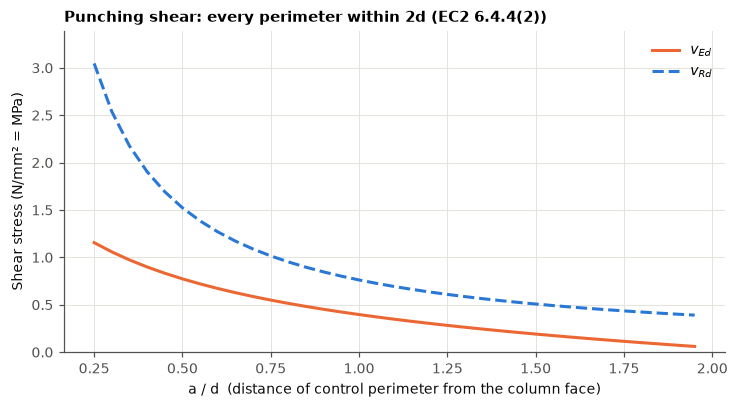

### 8. Punching shear within 2d

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Critical perimeter: $a_{cr}$ | $a_{cr} = 445.5$ mm |
| EC2 Exp. (6.51) | $v_{Ed,p}$ | $v_{Ed,p} = 0.549$ N/mm²<br><small>(= 0.549 MPa)</small> |
| EC2 Exp. (6.50) | $v_{Rd,p}$ | $v_{Rd,p} = 1.016$ N/mm²<br><small>(= 1.016 MPa)</small> |
| EC2 6.4.4(2) | **Check:** punching, worst of 35 perimeters<br>$v_{Ed,p} = 0.549 \le v_{Rd,p} = 1.016$ N/mm²<br><small>(= 0.549 ≤ 1.016 MPa)</small> | ✅ **PASS**<br>ratio 0.54 |


### 9. Cracking

| Reference | Calculation | Output |
|:--|:--|:--|
| EN 1990 Table A1.1 | Quasi-permanent factor: $\psi_{2}$ | $\psi_{2} = 0.3$  |
|  | $A_{s,ult}$ | $A_{s,ult} = 661.5$ mm² |
| EN 1990 (6.16b); method as JRC EUR 26566 (2014) 3.3.1.3 | Steel stress, quasi-permanent load<br>$\sigma_{s} = \dfrac{\dfrac{\dfrac{f_{yd}\,\left(G_{k} + \psi_{2}\,Q_{k}\right)}{1.35\,G_{k} + 1.5\,Q_{k}}\,A_{s,ult}}{A_{s,prov}}}{\delta}$<br>$\quad = \dfrac{\dfrac{\dfrac{434.8\times \left(772 + 0.3\times 421.3\right)}{1.35\times 772 + 1.5\times 421.3}\times 661.5}{1005.3}}{1}$ | $\mathbf{\sigma_{s} = 153.5}$ N/mm²<br><small>(= 153.5 MPa)</small> |
| EC2 Table 7.3N, NA.4 | Maximum bar spacing, w_k = 0.3 mm (next higher tabulated stress, no interpolation): $s_{crack}$ | $s_{crack} = 300$ mm |
|  | Bar spacing provided (centres): $s_{bars}$ | $s_{bars} = 200$ mm |
| EC2 7.3.3(2) | **Check:** crack control<br>$s_{bars} = 200 \le s_{crack} = 300$ mm | ✅ **PASS**<br>ratio 0.67 |


### 10. Starter bars

| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 8.4.3(2) | Design bar stress: $\sigma_{sd}$ | $\sigma_{sd} = 434.8$ N/mm²<br><small>(= 434.8 MPa)</small> |
| EC2 Exp. (8.3) | $l_{b,rqd} = \dfrac{\dfrac{\phi}{4}\,\sigma_{sd}}{f_{bd}}$<br>$\quad = \dfrac{\dfrac{16}{4}\times 434.8}{3.041}$ | $\mathbf{l_{b,rqd} = 571.8}$ mm |
| EC2 Exp. (8.6)/(8.7) | Compression: $f_{lmin}$ | $f_{lmin} = 0.6$  |
| EC2 8.4.4(1) | $l_{b,min} = \max\left\{f_{lmin}\,l_{b,rqd};\; 10\,\phi;\; 100\right\}$<br>$\quad = \max\left\{0.6\times 571.8;\; 10\times 16;\; 100\right\}$ | $\mathbf{l_{b,min} = 343.1}$ mm |
| EC2 Exp. (8.4) | $l_{bd} = \max\left\{\alpha_{2}\,l_{b,rqd};\; l_{b,min}\right\}$<br>$\quad = \max\left\{1\times 571.8;\; 343.1\right\}$ | $\mathbf{l_{bd} = 571.8}$ mm |
|  | Straight depth above the mat (bends do not count in compression, EC2 8.4.1(3))<br>$l_{av} = h - c_{nom} - 2\times 16$<br>$\quad = 650 - 40 - 2\times 16$ | $\mathbf{l_{av} = 578}$ mm |
| EC2 8.4.4 | **Check:** starter bar anchorage<br>$l_{av} = 578 \ge l_{bd} = 571.8$ mm | ✅ **PASS**<br>ratio 0.99 |
| EC2 Exp. (8.6)/(8.7) | Tension: $f_{lmin}$ | $f_{lmin} = 0.3$  |
| EC2 8.4.4(1) | $l_{b,min} = \max\left\{f_{lmin}\,l_{b,rqd};\; 10\,\phi;\; 100\right\}$<br>$\quad = \max\left\{0.3\times 571.8;\; 10\times 16;\; 100\right\}$ | $\mathbf{l_{b,min} = 171.6}$ mm |
| EC2 Exp. (8.4) | $l_{bd} = \max\left\{\alpha_{2}\,l_{b,rqd};\; l_{b,min}\right\}$<br>$\quad = \max\left\{1\times 571.8;\; 171.6\right\}$ | $\mathbf{l_{bd} = 571.8}$ mm |
| EC2 8.7.3 | 100% lapped: $\alpha_{6}$ | $\alpha_{6} = 1.5$  |
| EC2 Exp. (8.10), (8.11) | $l_{0,lap} = \max\left\{\alpha_{2}\,\alpha_{6}\,l_{b,rqd};\; 0.3\,\alpha_{6}\,l_{b,rqd};\; 15\,\phi;\; 200\right\}$<br>$\quad = \max\left\{1\times 1.5\times 571.8;\; 0.3\times 1.5\times 571.8;\; 15\times 16;\; 200\right\}$ | $\mathbf{l_{0,lap} = 857.8}$ mm |
|  | **PROVIDE: 8H16 starters, lap 875 mm above the pad** | 🟦 **8H16 starters, lap 875 mm above the pad** |


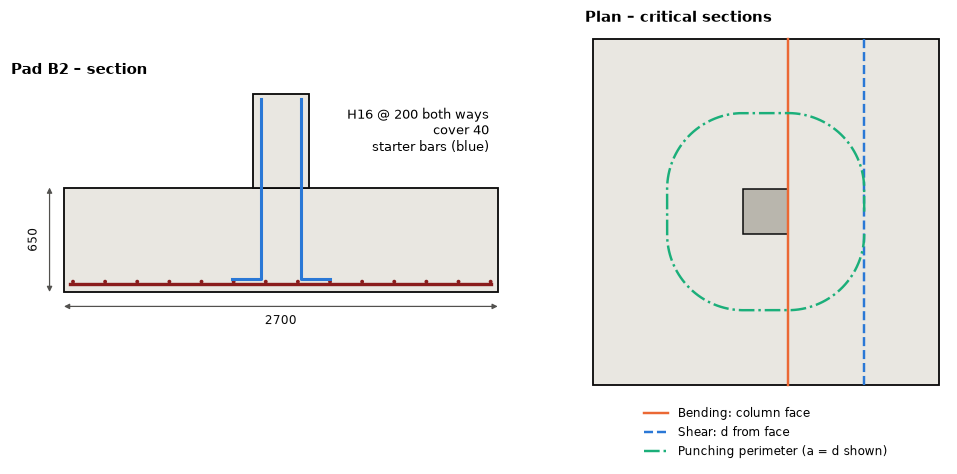

### Summary of checks

| Check | Reference | Ratio | Result |
|:--|:--|:-:|:--|
| resultant within the middle third | Statics; EN 1997-1 6.5.4 | 0.01 | ✅ PASS |
| bearing pressure | EN 1997-1 6.5.2.4 | 0.95 | ✅ PASS |
| nominal cover | EC2 4.4.1 | 1.00 | ✅ PASS |
| singly reinforced (inner layer, both directions detailed alike) | EC2 5.5(4) | 0.09 | ✅ PASS |
| minimum bar in a footing | EC2 9.8.2.1(1) | 0.50 | ✅ PASS |
| bending steel | EC2 6.1, 9.2.1.1 | 0.88 | ✅ PASS |
| steel for the inclined-crack model | EC2 9.8.2.2 | 0.76 | ✅ PASS |
| straight bar anchorage | EC2 9.8.2.2 | 0.70 | ✅ PASS |
| one-way shear, no links | EC2 6.2.2 | 0.61 | ✅ PASS |
| punching at the column face | EC2 6.4.5(3) | 0.38 | ✅ PASS |
| punching, worst of 35 perimeters | EC2 6.4.4(2) | 0.54 | ✅ PASS |
| crack control | EC2 7.3.3(2) | 0.67 | ✅ PASS |
| starter bar anchorage | EC2 8.4.4 | 0.99 | ✅ PASS |

**All checks pass.**

In [5]:
s = pad_design("B2", "B", 1, **pad)